In [1]:
# Import libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score
import matplotlib.pyplot as plt

In [2]:
# Import data
data = pd.read_csv("breast-cancer-data.csv")
data

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [3]:
data.isna().any()
data = data.loc[:, ~data.columns.str.contains('^Unnamed')]
data = data.dropna(axis=1)

In [4]:
# Extract classification target
target = data.loc[:, "diagnosis"]
# Convert the target variable to a binary representation (0 or 1)
target = (target == "M").astype(int)
# Extract all other columns except 'diagnosis' as predictors
data_predictors = data.loc[:, data.columns != 'diagnosis']
# Create a list of predictor names
predictor_names = data_predictors.columns

In [5]:
# Split data
x_train, x_test, y_train, y_test = train_test_split(data_predictors, target, test_size=0.3, random_state=0)

Generate initial population

In [6]:
def generate_random_individuals(population_size, num_features, min_features, max_features):
    individuals = np.zeros((population_size, num_features))
    for i in range(population_size):
        num_ones = np.random.randint(min_features, max_features + 1)
        ones_indices = np.random.choice(num_features, num_ones, replace=False)
        individuals[i, ones_indices] = 1
    return individuals    

Train model and get precision

In [7]:
def train_model(x_train, x_test, y_train, y_test, predictor_names):
    x_train = x_train.loc[:, predictor_names]
    x_test = x_test.loc[:, predictor_names]

    #Buildinng the random forest model 
    mdl = RandomForestClassifier(random_state=1) # Creating the random forest classifier model
    mdl.fit(x_train,y_train)
    y_hat = mdl.predict(x_test)
    prec = precision_score(y_test,y_hat)
    return prec

In [8]:
def choose_parents(population,accuracy,elite_percent):
    elite_num = int(round(((elite_percent*population.shape[0])//2)*2))
    ind_ac = np.argsort(-accuracy)
    top_perc = ind_ac[:elite_num]
    elite_population = population[top_perc,:]


    weight_norm = accuracy / accuracy.sum()
    weight_comu = weight_norm.cumsum()

    num_parents_wo_elite = population.shape[0] - elite_num
    parents_wo_elite = np.empty([num_parents_wo_elite,population.shape[1]])

    for count in range(num_parents_wo_elite):
        b = weight_comu[-1]
        rand_num = np.random.uniform(0,b)

        indices = np.searchsorted(weight_comu,rand_num)
        parents_wo_elite[count,:] = population[indices,:]

    parents = np.concatenate((elite_population,parents_wo_elite), axis=0)
    return parents

In [9]:
def one_point_crossover(parents,elite_percent,mutation_probability,min_features, max_features):
    elite_num = int(round(((elite_percent*population.shape[0]) // 2) * 2))
    crossover_population = np.zeros((parents.shape[0],parents.shape[1]))         # first two are elite
    crossover_population[0:elite_num,:] = parents[0:elite_num,:]
    
    for ii in range(int((parents.shape[0]-elite_num)/2)):
        n = 2*ii+elite_num                    # gives even number
        parents_couple = parents[n:n+2, :]    # comb of parents
        b2 = parents.shape[1]                 # num of features
        rand_n = np.random.randint(1, b2-1)   # generate rand number from 1 to num_of_features-1
        crossover_population[n,:] = np.concatenate([parents_couple[0, :rand_n], parents_couple[1, rand_n:]])
        crossover_population[n+1,:] = np.concatenate([parents_couple[1, :rand_n], parents_couple[0, rand_n:]])
        
    #check if every child has minimum number of features or all true values
    for kk in range(crossover_population.shape[0]):
        Sum = np.sum(crossover_population[kk,:])
        if Sum > max_features:
            # if the number of 1s is bigger than max number of features
            excess = int(Sum - max_features)
            indices = np.where(crossover_population[kk,:] == 1)[0]
            position1 = np.random.choice(indices, size=excess, replace=False)       
            crossover_population[kk, position1] = 0 # put 0s in random positions
        elif Sum < min_features:
            # if the number of 1s is smaller than min number of features
            missing = int(min_features - Sum)
            indices = np.where(crossover_population[kk,:] == 0)[0]
            position2 = np.random.choice(indices, size=missing, replace=False) 
            crossover_population[kk, position2] = 1 # put 1s in random positions

    # mutation
    child_row = crossover_population.shape[0]
    child_col = crossover_population.shape[1]
    num_mutations = round(child_row*child_col*mutation_probability)     
    for jj in range(num_mutations):
        ind_row = np.random.randint(0,child_row) # random number btw 0 and num of rows
        ind_col = np.random.randint(0,child_col) # random number btw 0 and num of colmns
        if (crossover_population[ind_row,ind_col] == 0 and 
            np.sum(crossover_population[ind_row,:]) < max_features):
            crossover_population[ind_row,ind_col] = 1
        elif (crossover_population[ind_row,ind_col] == 1 and 
              np.sum(crossover_population[ind_row,:]) >= min_features+1):
            crossover_population[ind_row,ind_col] = 0 
    
    return crossover_population 

In [10]:
# Hyperparameters
num_features = data_predictors.shape[1]
min_features = 2            # minimal number of features in a subset of features
population_size = 8         # size of population (number of instances)
max_iterations = 8          # maximum number of iterations
elite_percent = 0.4         # percentage of elite population which doesn't mutate
mutation_probability = 0.2  # percentage of total genes that mutate
max_features = 4            # maximum number of features in a subset of features

Main Genetic Algorithm

In [11]:
# Main loop - gen 0
#1&2 generate population
population = generate_random_individuals(population_size, num_features, min_features, max_features)   
#3&4 train model
accuracy = np.zeros(population_size);   
predictor_names = data_predictors.columns
response_name = target.name                                                 
for i in range(population_size):
    predictor_names_i = predictor_names[population[i,:]==1]
    accuracy_i = train_model(x_train,x_test,y_train,y_test,predictor_names_i)
    accuracy[i] = accuracy_i
gen = 0
best_acc_i = np.zeros(max_iterations)    
best_acc_i[gen] = max(accuracy)     # keep best accuracy from 1st gen

# Main loop - gen > 0
while gen < max_iterations-1:
    print('Begin iteration num {}/{}'.format(gen+2,max_iterations))
    gen += 1
    parents = choose_parents(population, accuracy, elite_percent)
    children = one_point_crossover(parents,elite_percent,mutation_probability,min_features,max_features)
    population = children
    for ind in range(population_size):
        predictor_names_ind = predictor_names[population[ind,:]==1]
        accuracy_ind = train_model(x_train,x_test,y_train,y_test,predictor_names_ind)
        accuracy[ind] = accuracy_ind
    best_acc_i[gen] = max(accuracy)
    
ind_max_acc = np.argmax(accuracy)
best_features = population[ind_max_acc,:]

Begin iteration num 2/8
Begin iteration num 3/8
Begin iteration num 4/8
Begin iteration num 5/8
Begin iteration num 6/8
Begin iteration num 7/8
Begin iteration num 8/8


Plot

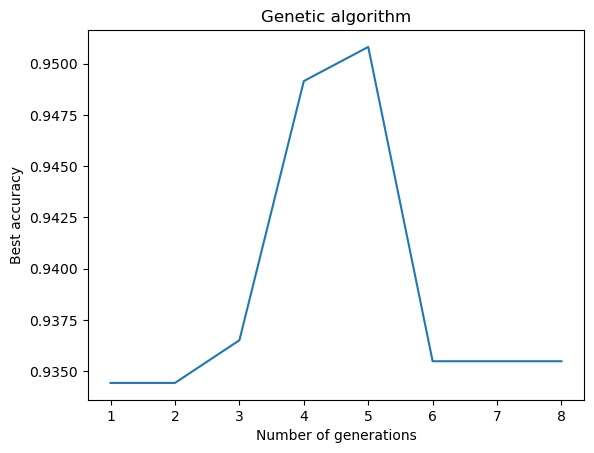

In [12]:
# Plots - Post-processing
best_features_names = predictor_names[best_features==1]
plt.plot(range(1, max_iterations + 1), best_acc_i)
plt.xlabel('Number of generations')
plt.ylabel('Best accuracy')
plt.title('Genetic algorithm')
plt.show()